
# NLP Sentiment Classification on Customer Reviews (TF-IDF)

## 1. Project Overview

This project builds a Natural Language Processing (NLP) model to classify customer reviews based on their sentiment.

The project uses text preprocessing, TF-IDF vectorization, and machine learning classification algorithms to identify sentiment from review text.

## Objectives

- Load and explore the customer reviews dataset.
- Clean and preprocess textual data.
- Convert text into numerical features using TF-IDF.
- Train Multinomial Naive Bayes and Logistic Regression models.
- Evaluate and compare model performance.
- Predict sentiment for custom user-input reviews.


In [15]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
df = pd.read_csv("sentiment_reviews.csv")

# Display the first five rows
display(df.head())

# Check dataset size and column names
print("Dataset shape:", df.shape)
print("\nColumn names:", df.columns.tolist())


,review_id,review_text,sentiment
0,1,"The product quality is exceptional, exceeded a...",positive
1,2,Terrible customer service and the item arrived...,negative
2,3,"Average performance, decent for the price poin...",neutral
3,4,"Absolutely love this! Easy to setup, robust, a...",positive
4,5,Stopped working after two days. Extremely disa...,negative


Dataset shape: (10, 3)

Column names: ['review_id', 'review_text', 'sentiment']



## 2. Dataset Exploration

In this step, we examine the structure and quality of the customer reviews dataset.

We will:
- Check the number of rows and columns.
- Inspect column data types.
- Identify missing values and duplicate records.
- Examine the distribution of sentiment labels.


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   review_id    10 non-null     int64 
 1   review_text  10 non-null     object
 2   sentiment    10 non-null     object
dtypes: int64(1), object(2)
memory usage: 372.0+ bytes

Missing Values:
review_id      0
review_text    0
sentiment      0
dtype: int64

Duplicate Rows: 0

Sentiment Distribution:
sentiment
positive    5
negative    4
neutral     1
Name: count, dtype: int64


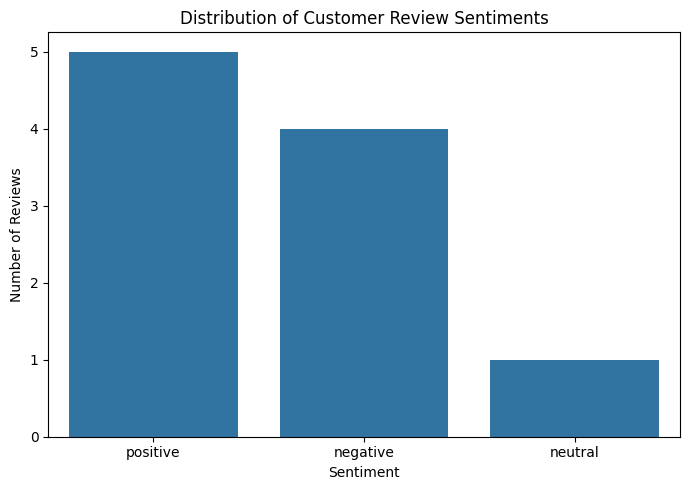

In [16]:

# Dataset information
print("Dataset Information:")
df.info()

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate Rows:", df.duplicated().sum())

# Display sentiment distribution
print("\nSentiment Distribution:")
print(df["sentiment"].value_counts())

# Visualize sentiment distribution
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="sentiment")
plt.title("Distribution of Customer Review Sentiments")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()



## 3. Data Cleaning

In this step, we prepare the dataset for sentiment classification.

We will:
- Remove rows with missing review text or sentiment labels.
- Remove duplicate records.
- Convert review text into string format.
- Check the dataset after cleaning.


In [17]:

# Create a copy of the original dataset
df_clean = df.copy()

# Remove rows with missing review text or sentiment
df_clean = df_clean.dropna(subset=["review_text", "sentiment"])

# Remove duplicate records
df_clean = df_clean.drop_duplicates()

# Convert review text to string and remove extra spaces
df_clean["review_text"] = df_clean["review_text"].astype(str).str.strip()

# Remove empty reviews
df_clean = df_clean[df_clean["review_text"] != ""]

# Reset the index
df_clean = df_clean.reset_index(drop=True)

# Display cleaning results
print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", df_clean.shape)
print("Missing values after cleaning:")
print(df_clean[["review_text", "sentiment"]].isnull().sum())

# Display a few cleaned reviews
display(df_clean.head())


Original dataset shape: (10, 3)
Cleaned dataset shape: (10, 3)
Missing values after cleaning:
review_text    0
sentiment      0
dtype: int64


,review_id,review_text,sentiment
0,1,"The product quality is exceptional, exceeded a...",positive
1,2,Terrible customer service and the item arrived...,negative
2,3,"Average performance, decent for the price poin...",neutral
3,4,"Absolutely love this! Easy to setup, robust, a...",positive
4,5,Stopped working after two days. Extremely disa...,negative



## 4. Text Preprocessing

Text preprocessing prepares customer reviews for machine learning.

In this step, we will:
- Convert review text to lowercase.
- Remove URLs and HTML tags.
- Remove unnecessary punctuation and special characters.
- Normalize extra spaces.

The cleaned text will be used for TF-IDF feature extraction.


In [18]:

import re

def clean_text(text):
    # Convert text to lowercase
    text = text.lower()

    # Remove URLs
    text = re.sub(r"http\S+|www\.\S+", "", text)

    # Remove HTML tags
    text = re.sub(r"<.*?>", " ", text)

    # Keep letters, numbers, and spaces
    text = re.sub(r"[^a-zA-Z0-9\s]", " ", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    return text

# Apply text cleaning
df_clean["cleaned_text"] = df_clean["review_text"].apply(clean_text)

# Compare original and cleaned reviews
display(df_clean[["review_text", "cleaned_text", "sentiment"]].head())

print("Total reviews after preprocessing:", len(df_clean))


,review_text,cleaned_text,sentiment
0,"The product quality is exceptional, exceeded a...",the product quality is exceptional exceeded al...,positive
1,Terrible customer service and the item arrived...,terrible customer service and the item arrived...,negative
2,"Average performance, decent for the price poin...",average performance decent for the price point...,neutral
3,"Absolutely love this! Easy to setup, robust, a...",absolutely love this easy to setup robust and ...,positive
4,Stopped working after two days. Extremely disa...,stopped working after two days extremely disap...,negative


Total reviews after preprocessing: 10



## 5. Train-Test Split and TF-IDF Vectorization

In this step, we divide the dataset into training and testing sets.

- **Training set:** Used to train the machine learning models.
- **Testing set:** Used to evaluate model performance on unseen reviews.
- **TF-IDF:** Converts text reviews into numerical features based on the importance of words.

We will use an 80:20 train-test split and fit the TF-IDF vectorizer only on the training data to avoid data leakage.


In [19]:

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

# Define input features and target labels
X = df_clean["cleaned_text"]
y = df_clean["sentiment"]

# Split into training and testing sets
# stratify is omitted because the neutral class has only one review
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=42
)

# Convert text into TF-IDF features
tfidf = TfidfVectorizer(max_features=5000, ngram_range=(1, 2))

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

# Display results
print("Training reviews:", len(X_train))
print("Testing reviews:", len(X_test))
print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)

print("\nSentiment classes in full dataset:")
print(y.value_counts())

print("\nSentiment classes in training data:")
print(y_train.value_counts())


Training reviews: 7
Testing reviews: 3
Training TF-IDF shape: (7, 119)
Testing TF-IDF shape: (3, 119)

Sentiment classes in full dataset:
sentiment
positive    5
negative    4
neutral     1
Name: count, dtype: int64

Sentiment classes in training data:
sentiment
positive    4
negative    2
neutral     1
Name: count, dtype: int64


In [20]:

print("Total cleaned reviews:", len(df_clean))

print("\nReviews in each sentiment class:")
print(df_clean["sentiment"].value_counts())

print("\nNumber of sentiment classes:", df_clean["sentiment"].nunique())


Total cleaned reviews: 10

Reviews in each sentiment class:
sentiment
positive    5
negative    4
neutral     1
Name: count, dtype: int64

Number of sentiment classes: 3



## 6. Model Training — Multinomial Naive Bayes

Multinomial Naive Bayes is a machine learning algorithm commonly used for text classification.

In this step, we will:
- Initialize the Multinomial Naive Bayes classifier.
- Train it using the TF-IDF features.
- Predict sentiment labels for the test reviews.

The trained model will be used in the next step to evaluate sentiment classification performance.


In [21]:

from sklearn.naive_bayes import MultinomialNB

# Initialize the model
nb_model = MultinomialNB()

# Train the model
nb_model.fit(X_train_tfidf, y_train)

# Predict sentiments for test reviews
y_pred_nb = nb_model.predict(X_test_tfidf)

print("Multinomial Naive Bayes model trained successfully!")
print("Number of test reviews:", len(y_test))

print("\nActual sentiments:")
print(y_test.tolist())

print("\nPredicted sentiments:")
print(y_pred_nb.tolist())


Multinomial Naive Bayes model trained successfully!
Number of test reviews: 3

Actual sentiments:
['negative', 'negative', 'positive']

Predicted sentiments:
['positive', 'positive', 'positive']



## 7. Model Evaluation

In this step, we evaluate the performance of the Multinomial Naive Bayes classifier.

We will use:
- **Accuracy:** The proportion of correct predictions.
- **Precision:** How many predicted instances of a sentiment are correct.
- **Recall:** How many actual instances of a sentiment are identified correctly.
- **F1-score:** The harmonic mean of precision and recall.
- **Confusion Matrix:** A table comparing actual and predicted sentiment labels.

Because the dataset contains only 10 reviews, the evaluation results should be interpreted cautiously.


Multinomial Naive Bayes Evaluation
----------------------------------------
Accuracy: 33.33%

Classification Report:
              precision    recall  f1-score   support

    negative       0.00      0.00      0.00         2
     neutral       0.00      0.00      0.00         0
    positive       0.33      1.00      0.50         1

    accuracy                           0.33         3
   macro avg       0.11      0.33      0.17         3
weighted avg       0.11      0.33      0.17         3



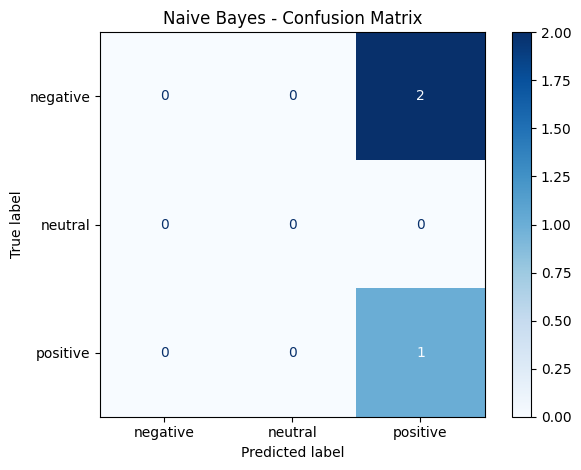

In [22]:

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Calculate accuracy
accuracy_nb = accuracy_score(y_test, y_pred_nb)

print("Multinomial Naive Bayes Evaluation")
print("-" * 40)
print(f"Accuracy: {accuracy_nb:.2%}")

# Display precision, recall, and F1-score
print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_nb,
        labels=nb_model.classes_,
        zero_division=0
    )
)

# Plot confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred_nb,
    labels=nb_model.classes_
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=nb_model.classes_
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Naive Bayes - Confusion Matrix")
plt.tight_layout()
plt.show()



## 8. Model Training — Logistic Regression

Logistic Regression is a supervised machine learning algorithm used for classification tasks.

In this step, we will:
- Initialize the Logistic Regression classifier.
- Train the model using TF-IDF features.
- Predict sentiments for the test reviews.
- Prepare the predictions for model comparison.


In [23]:

from sklearn.linear_model import LogisticRegression

# Initialize the Logistic Regression model
lr_model = LogisticRegression(max_iter=1000, random_state=42)

# Train the model
lr_model.fit(X_train_tfidf, y_train)

# Predict sentiments for test reviews
y_pred_lr = lr_model.predict(X_test_tfidf)

print("Logistic Regression model trained successfully!")

print("\nActual sentiments:")
print(y_test.tolist())

print("\nPredicted sentiments:")
print(y_pred_lr.tolist())


Logistic Regression model trained successfully!

Actual sentiments:
['negative', 'negative', 'positive']

Predicted sentiments:
['positive', 'positive', 'positive']



## 9. Model Performance Comparison

In this step, we compare Multinomial Naive Bayes and Logistic Regression.

We will compare the models using:
- Accuracy
- Weighted Precision
- Weighted Recall
- Weighted F1-score

A comparison chart will help visualize the evaluation results and identify which model performs better on the test set.

Note: The dataset contains only 10 reviews, so these results are preliminary and cannot establish which model is generally better.


,Model,Accuracy,Precision,Recall,F1-Score
0,Multinomial Naive Bayes,0.333,0.111,0.333,0.167
1,Logistic Regression,0.333,0.111,0.333,0.167


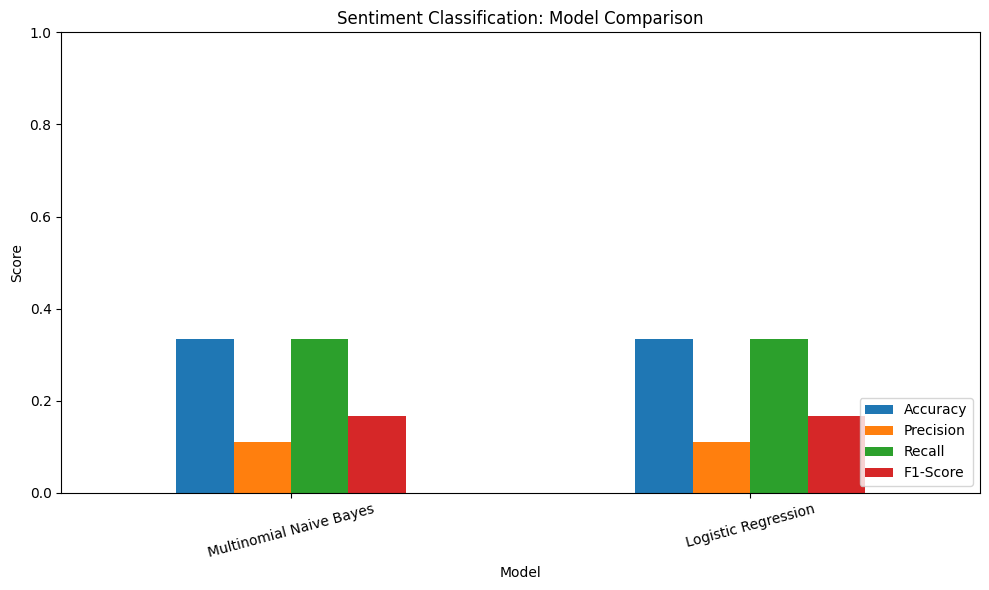

In [24]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd
import matplotlib.pyplot as plt

# Calculate evaluation metrics for both models
results = []

for model_name, predictions in [
    ("Multinomial Naive Bayes", y_pred_nb),
    ("Logistic Regression", y_pred_lr)
]:
    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, average="weighted", zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, average="weighted", zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, predictions, average="weighted", zero_division=0
        )
    })

comparison_df = pd.DataFrame(results)

# Display comparison table
display(comparison_df.round(3))

# Plot model comparison
comparison_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1-Score"]
].plot(kind="bar", figsize=(10, 6), ylim=(0, 1))

plt.title("Sentiment Classification: Model Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.xticks(rotation=15)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()



## 10. Sentiment Prediction on Custom Reviews

In this step, we use the trained models to predict the sentiment of new customer reviews.

Users can enter their own review text, and the model will classify it into one of the sentiment categories learned from the training data.

This demonstrates how the trained NLP model can be used on previously unseen text.


In [25]:

# Function to predict sentiment for a new review
def predict_sentiment(review, model=lr_model):
    # Clean the input review
    cleaned_review = clean_text(review)

    # Convert the review using the already-trained TF-IDF vectorizer
    review_tfidf = tfidf.transform([cleaned_review])

    # Predict sentiment
    prediction = model.predict(review_tfidf)[0]

    return prediction


# Try sample customer reviews
sample_reviews = [
    "The product is excellent and I am very happy",
    "The quality is terrible and I am disappointed",
    "The product is okay, nothing special"
]

for review in sample_reviews:
    predicted_sentiment = predict_sentiment(review)

    print("Review:", review)
    print("Predicted Sentiment:", predicted_sentiment)
    print("-" * 50)


Review: The product is excellent and I am very happy
Predicted Sentiment: positive
--------------------------------------------------
Review: The quality is terrible and I am disappointed
Predicted Sentiment: positive
--------------------------------------------------
Review: The product is okay, nothing special
Predicted Sentiment: positive
--------------------------------------------------



## 11. Results and Conclusion

### Results

In this project, we developed a customer review sentiment classification system using Natural Language Processing (NLP).

The project includes:
- Dataset exploration and data cleaning.
- Text preprocessing using Python and regular expressions.
- TF-IDF feature extraction.
- Multinomial Naive Bayes classification.
- Logistic Regression classification.
- Evaluation using accuracy, precision, recall, and F1-score.
- Comparison of both models.
- Sentiment prediction for custom customer reviews.

### Conclusion

This project demonstrates how text data can be transformed into numerical features using TF-IDF and classified using machine learning algorithms.

Both Multinomial Naive Bayes and Logistic Regression were trained and evaluated. The comparison provides preliminary insights into their performance on the available dataset.

### Limitations

- The dataset contains only 10 reviews.
- Evaluation metrics may vary significantly because of the small test set.
- The models may not generalize well to real-world customer reviews.
- A larger, balanced, and representative dataset is required for reliable performance evaluation.

### Future Improvements

- Use a larger labeled customer review dataset.
- Apply cross-validation for more reliable model evaluation.
- Tune model hyperparameters.
- Build a simple web interface for interactive sentiment prediction.
- Evaluate the models on unseen real-world reviews.


In [26]:

print("=" * 55)
print("NLP SENTIMENT CLASSIFICATION - PROJECT SUMMARY")
print("=" * 55)

print("Dataset size:", len(df_clean), "reviews")
print("Features used: TF-IDF")
print("Models trained: Multinomial Naive Bayes, Logistic Regression")

print("\nModel Comparison:")
display(comparison_df.round(3))

print("Project workflow completed successfully!")


NLP SENTIMENT CLASSIFICATION - PROJECT SUMMARY
Dataset size: 10 reviews
Features used: TF-IDF
Models trained: Multinomial Naive Bayes, Logistic Regression

Model Comparison:


,Model,Accuracy,Precision,Recall,F1-Score
0,Multinomial Naive Bayes,0.333,0.111,0.333,0.167
1,Logistic Regression,0.333,0.111,0.333,0.167


Project workflow completed successfully!
